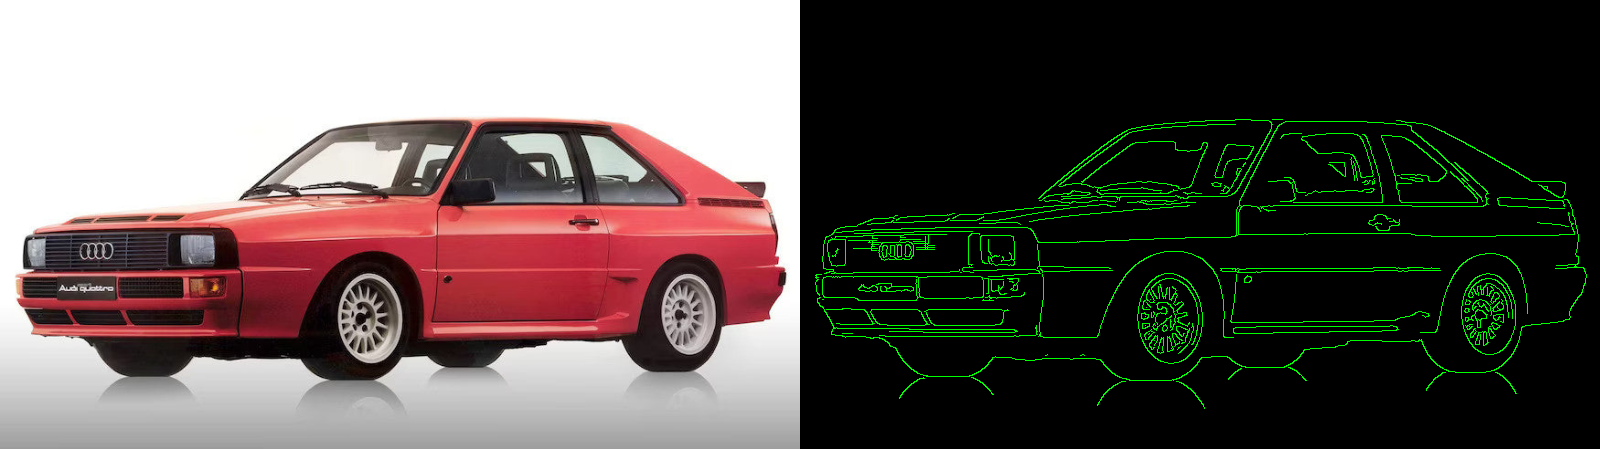

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img_path = '아우디 콰트로.jpeg'
srcimg = cv2.imread(img_path)

srcimg = cv2.resize(srcimg, (800, int(800 * srcimg.shape[0] / srcimg.shape[1])))

gray = cv2.cvtColor(srcimg, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (5, 5), 0)

edges = cv2.Canny(blurred, 50, 150)

edge_colored = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
edge_colored[edges !=0] = [0, 255, 0]

result_frame = np.hstack([srcimg, edge_colored])

cv2_imshow(result_frame)

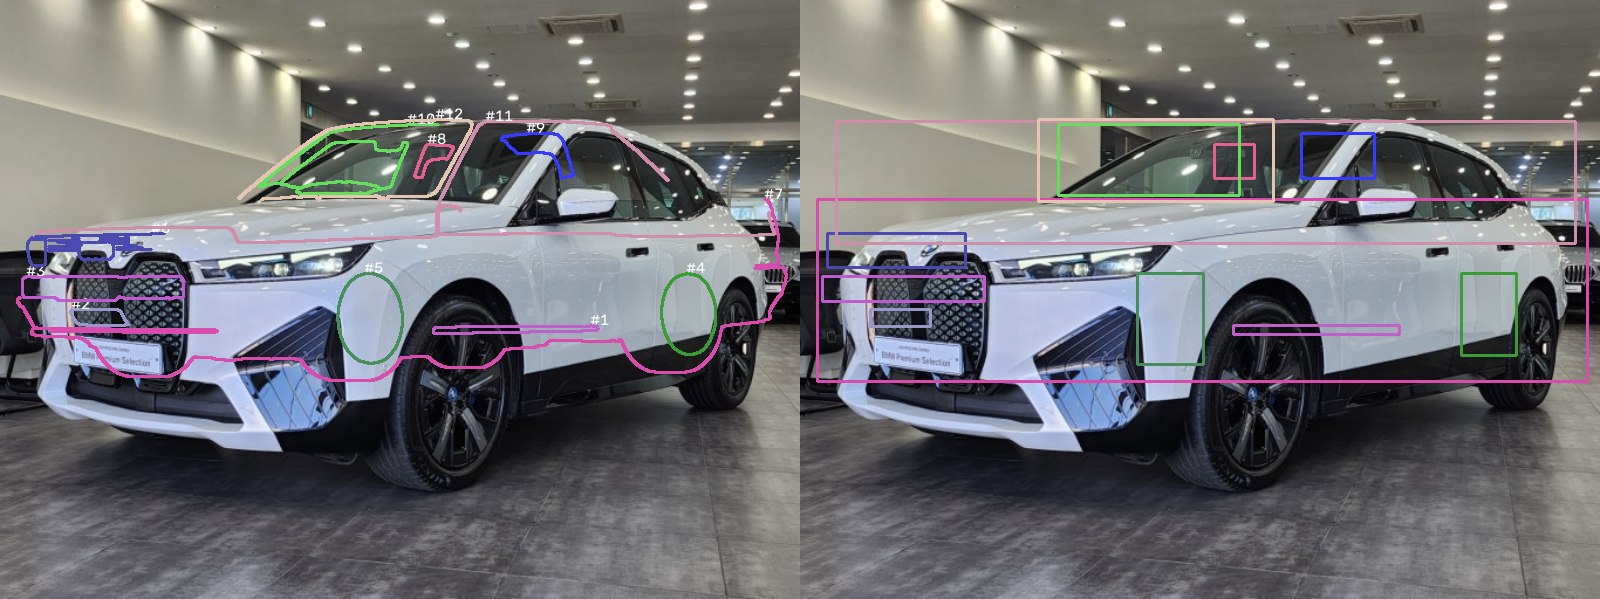

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img_path = 'bmw ix.jpeg'
srcimg = cv2.imread(img_path)

srcimg = cv2.resize(srcimg, (800, int(800 * srcimg.shape[0] / srcimg.shape[1])))

view_contours = srcimg.copy()
view_boxes = srcimg.copy()

gray = cv2.cvtColor(srcimg, cv2.COLOR_BGR2GRAY)
bluured = cv2.GaussianBlur(gray, (7, 7), 0)

edges = cv2.Canny(blurred, 40, 120)

contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

min_area = 100
valid_count = 0

for i, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    if area > min_area:
        valid_count += 1
        random_color = [int(c) for c in np.random.randint(50, 255, 3)]

        cv2.drawContours(view_contours, [cnt], -1, random_color, 2)
        cv2.putText(view_contours, f"#{valid_count}", tuple(cnt[0][0]),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)

        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(view_boxes, (x, y), (x + w, y + h), random_color, 2)

result_frame = np.hstack([view_contours, view_boxes])
cv2_imshow(result_frame)

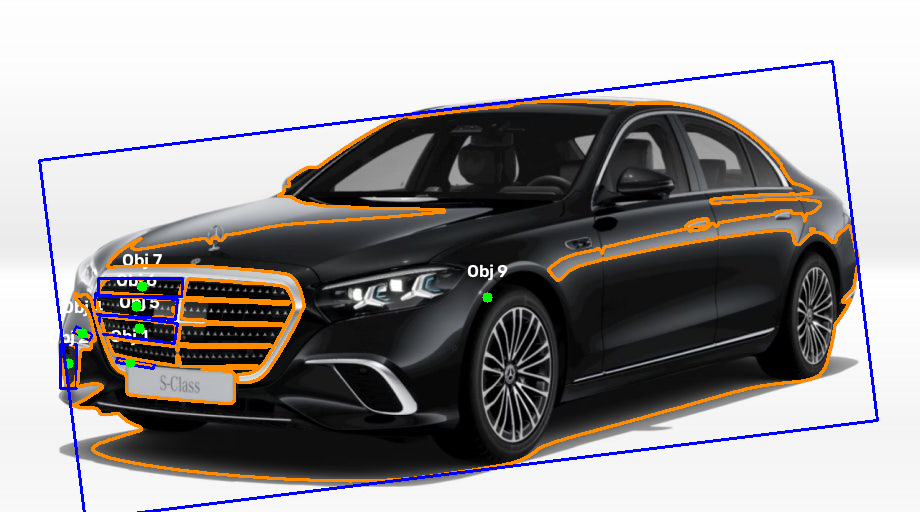

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image_path = '벤츠 마이바흐.jpeg'

with open(image_path, "rb") as f:
    chunk = f.read()
    bytes_arr = np.frombuffer(chunk, dtype=np.uint8)
    src_img = cv2.imdecode(bytes_arr, cv2.IMREAD_COLOR)

gray_img = cv2.cvtColor(src_img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray_img, (5, 5), 0)
_, thresh = cv2.threshold(blurred, 100, 255, cv2.THRESH_BINARY_INV)

contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output_img = src_img.copy()

for i, contour in enumerate(contours):
    if cv2.contourArea(contour) < 50:
        continue

    cv2.drawContours(output_img, [contour], -1, (0, 140, 255), 2)

    rect = cv2.minAreaRect(contour)
    box = cv2.boxPoints(rect)
    box = np.int32(box)
    cv2.drawContours(output_img, [box], 0, (255, 0, 0), 2)

    M = cv2.moments(contour)
    if M["m00"] != 0:
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])

        cv2.circle(output_img, (cX, cY), 5, (0, 255, 0), -1)
        text = "Obj " + str(i)
        cv2.putText(output_img, text, (cX - 20, cY - 20),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

cv2_imshow(output_img)

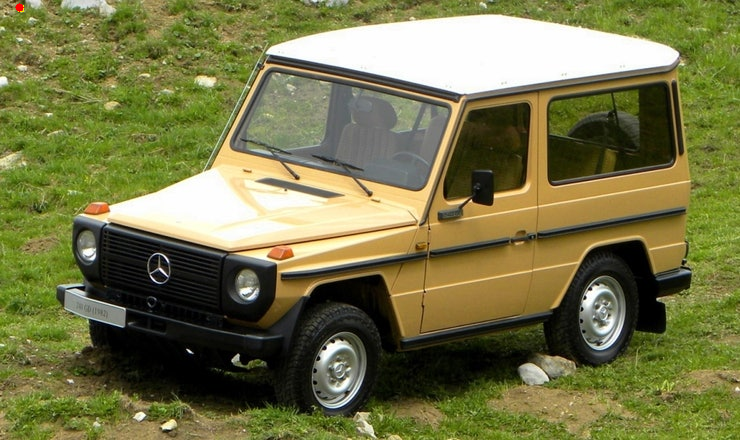

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image_path = '벤츠 G클래스.jpeg'

with open(image_path, "rb") as f :
    bytes_arr = np.frombuffer(f.read(), dtype=np.uint8)
    src_img = cv2.imdecode(bytes_arr, cv2.IMREAD_COLOR)

if src_img is None:
     src_img = np.zeros((600, 800, 3), dtype=np.uint8)

gray = cv2.cvtColor(src_img, cv2.COLOR_BGR2GRAY)
imthres = cv2.Canny(gray, 50, 150)

contours, _ = cv2.findContours(imthres, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

custom_output = src_img.copy()

for idx, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)

    if area < 1:
        continue

cv2.drawContours(custom_output, [cnt], -1, (0, 255, 180), 2)

x, y, w, h = cv2.boundingRect(cnt)
cv2.rectangle(custom_output, (x, y), (x + w, y + h), (0, 220, 255), 1)

M = cv2.moments(cnt)
if M["m00"] != 0:
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])

    cv2.circle(custom_output, (cx, cy), 4, (0, 0, 255), -1)

    info_text = f"#{idx} A:{int(area)}"
    cv2.putText(custom_output, info_text, (cx - 20, cy - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)

cv2_imshow(custom_output)

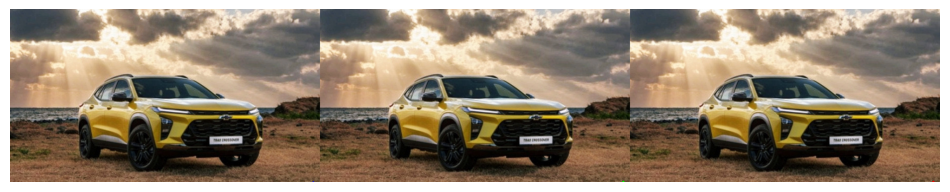

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image_path = '트렉스.jpeg'
image_bytes = np.fromfile(image_path, np.uint8)
img1 = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)

img1 = cv2.imread(image_path)

if img1 is None:
    print
else:

  img2 = img1.copy()
  img3 = img1.copy()

  gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
  ret, thresh = cv2.threshold(gray, 130, 255, cv2.THRESH_BINARY)

  contours, hierarchy = cv2.findContours(
      thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
  )

  if len(contours) > 0:
     target_contour = contours[0]

     epsilon_val1 = 0.04 * cv2.arcLength(target_contour, True)
     approx1 = cv2.approxPolyDP(target_contour, epsilon_val1, True)

     epsiolon_val2 = 0.08 * cv2.arcLength(target_contour, True)
     approx2 = cv2.approxPolyDP(target_contour, epsiolon_val2, True)

     cv2.drawContours(img1, [target_contour], -1, (255, 0, 0), 2)

     cv2.drawContours(img2, [approx1], -1, (0, 255, 0), 3)

     cv2.drawContours(img3, [approx2], -1, (0, 0, 255), 3)

     combined_frame = np.hstack((img1, img2, img3))

     import matplotlib.pyplot as pyplot

     combined_frame = np.hstack((img1, img2, img3))

     plt.figure(figsize=(12, 4))
     plt.imshow(cv2.cvtColor(combined_frame, cv2.COLOR_BGR2RGB))
     plt.axis('off')
     plt.show()

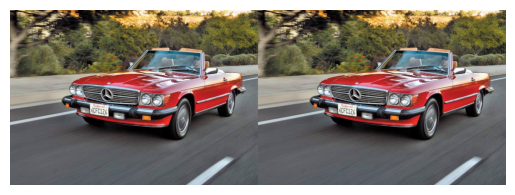

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('560SL.jpeg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, th = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)

contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cntr = contours[0]
hull_indices = cv2.convexHull(cntr,returnPoints=False)
defects = cv2.convexityDefects(cntr, hull_indices)

result = img.copy()
if defects is not None:
  for i in range(defects.shape[0]):
    _, _, f, dist = defects[i, 0]
    if (dist / 256.0) > 1:
      farthest = tuple(cntr[f][0])
      cv2.circle(result, farthest, 5, (0, 0, 255), -1)

comparison = np.hstack((img, result))
plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


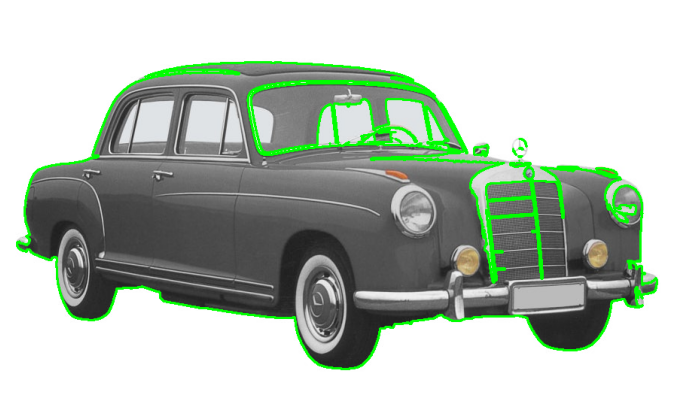

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

shapes = cv2.imread('220S.jpeg')

s_gray = cv2.cvtColor(shapes, cv2.COLOR_BGR2GRAY)
_, s_th = cv2.threshold(
    s_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

s_cnts, _ = cv2.findContours(s_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cv2.drawContours(result, s_cnts, -1, (0, 255, 0), 2)

result = shapes.copy()
cv2.drawContours(result, s_cnts, -1, (0, 255, 0), 2)

plt.figure(figsize=(10,5))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

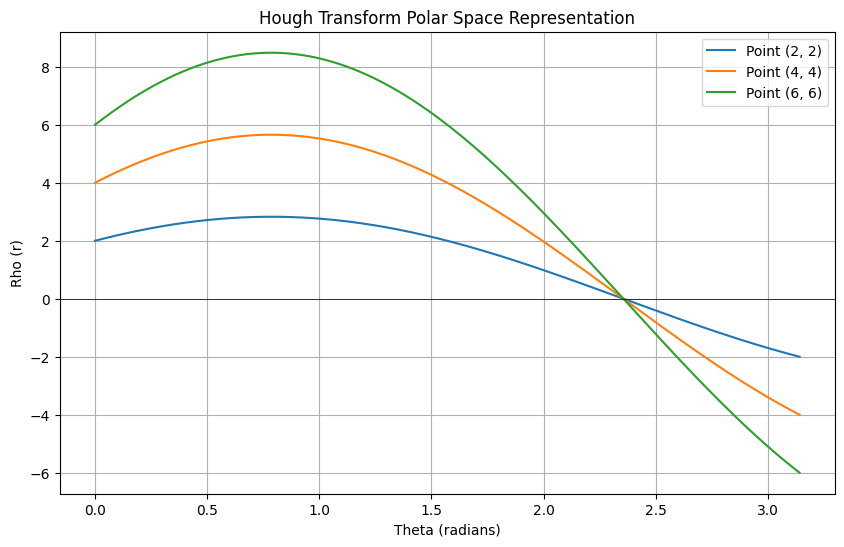

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

points = np.array([[2, 2], [4, 4], [6, 6]])

theta = np.linspace(0, np.pi, 500)

plt.figure(figsize=(10, 6))

for x, y in points:
  rho = x * np.cos(theta) + y * np.sin(theta)
  plt.plot(theta, rho, label=f'Point ({x}, {y})')

plt.title('Hough Transform Polar Space Representation')
plt.xlabel('Theta (radians)')
plt.ylabel('Rho (r)')
plt.axhline(0, color='black', linewidth=0.5)
plt.grid(True)
plt.legend()
plt.show()

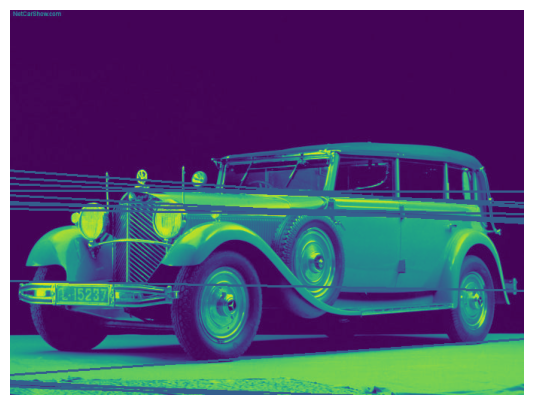

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('벤츠 770.jpeg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 250, 400)

lines = cv2.HoughLines(edges, 1, np.pi / 180, 130)

result = img.copy()
if lines is not None:
  for i in range(len(lines)):
    rho, theta = lines[i][0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))

    cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2GRAY))
plt.axis('off')
plt.show()

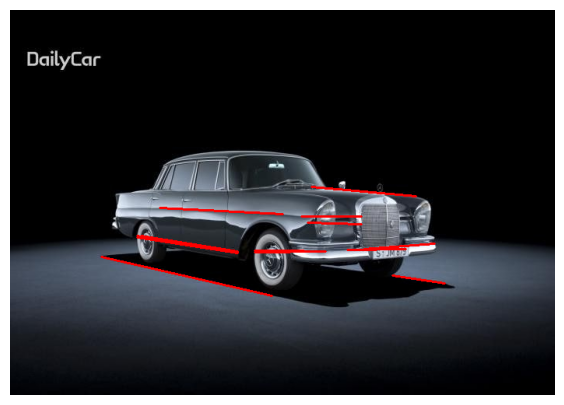

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('S클래스.jpeg')
img2 = img.copy()

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 200, 400)

lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=80,
    minLineLength=60,
    maxLineGap=15
)

if lines is not None:
  for line in lines:
    x1, y1, x2, y2 = line
    cv2.line(img2, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

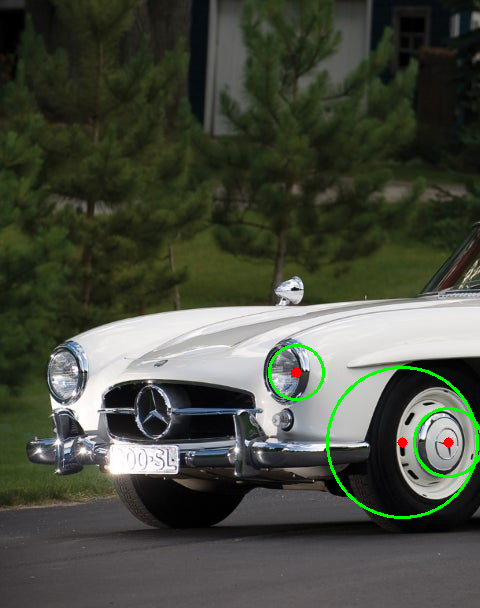

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('SL300.jpeg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (9, 9), 2)

circles = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=30,
    param1=100,
    param2=40,
    minRadius=10,
    maxRadius=150
)

if circles is not None:
  circles = np.uint16(np.around(circles))
  for i in circles[0, :]:

      cv2.circle(img, (i[0], i[1]), i[2], (0, 255, 0), 2)
      cv2.circle(img, (i[0], i[1]), 2, (0, 0, 255), 6)

cv2_imshow(img)

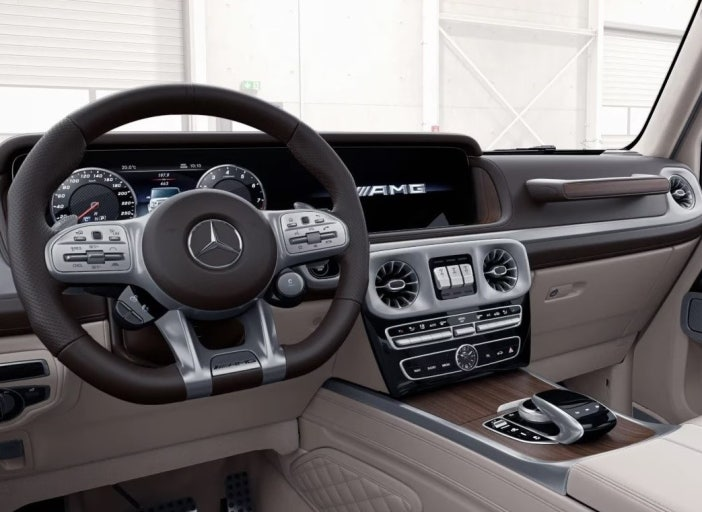

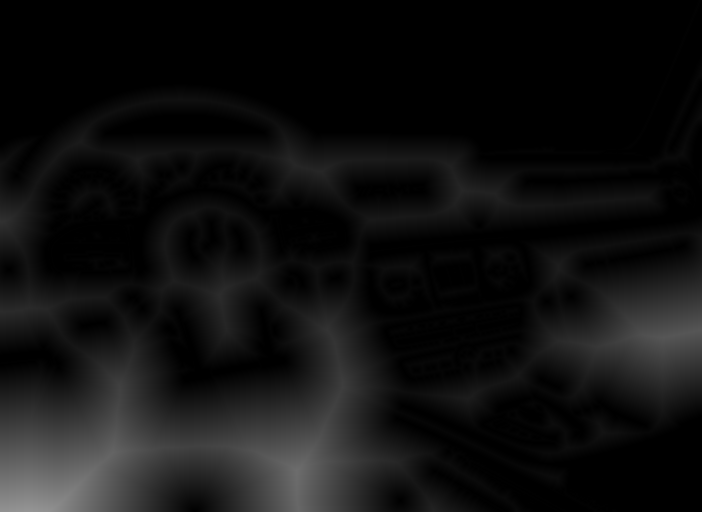

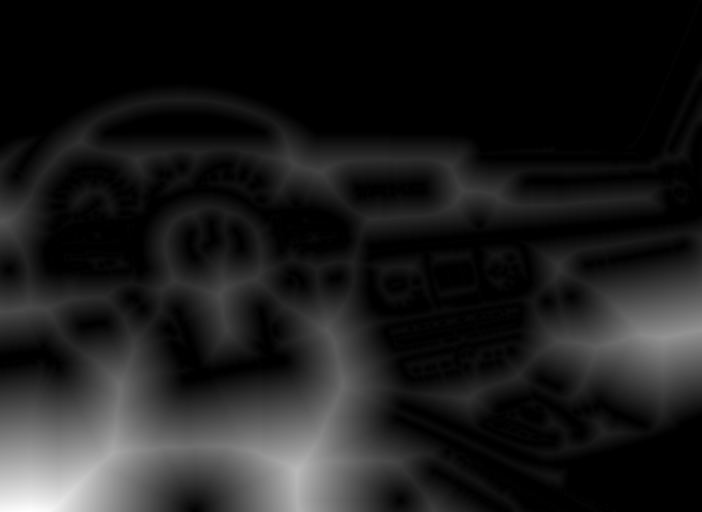

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_path = 'G63 AMG.jpeg'
img = cv2.imread(file_path)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

result = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)

print
cv2_imshow(img)

print
cv2_imshow(dist_transform)

print
cv2_imshow(result)

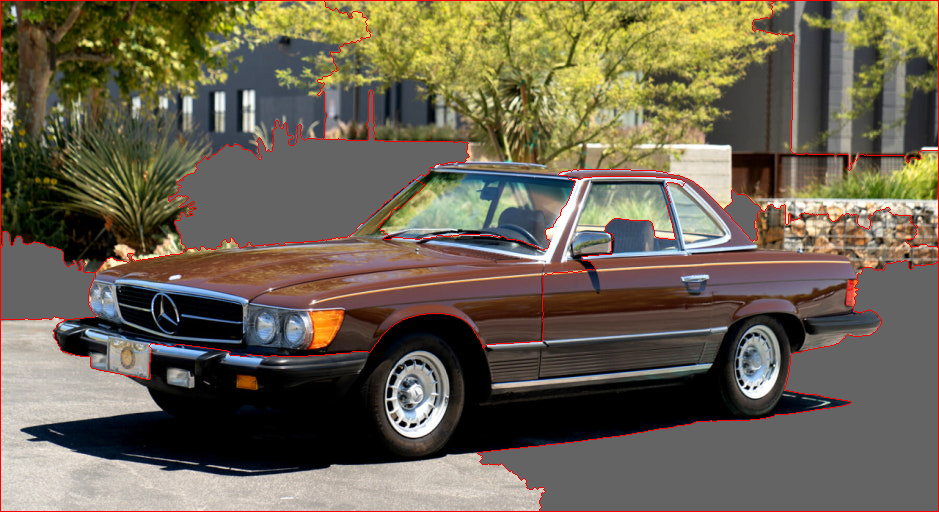

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_name = 'SL 450.jpeg'
image = cv2.imread(file_name)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY_INV)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
sure_background = cv2.dilate(binary, kernel)

dist_transform = cv2.distanceTransform(sure_background, cv2.DIST_L2, 5)
normalized_dist = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)
_, sure_foreground = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, cv2.THRESH_BINARY)

sure_fg_uint8 = np.uint8(sure_foreground)
unknown_region = cv2.subtract(sure_background, sure_fg_uint8)

_, markers = cv2.connectedComponents(sure_fg_uint8)
markers = markers + 1
markers[unknown_region == 255] = 0

markers = cv2.watershed(image, markers)

image[markers == -1] = [0, 0, 255]
image[markers == 1] = [100, 100, 100]

cv2_imshow(image)

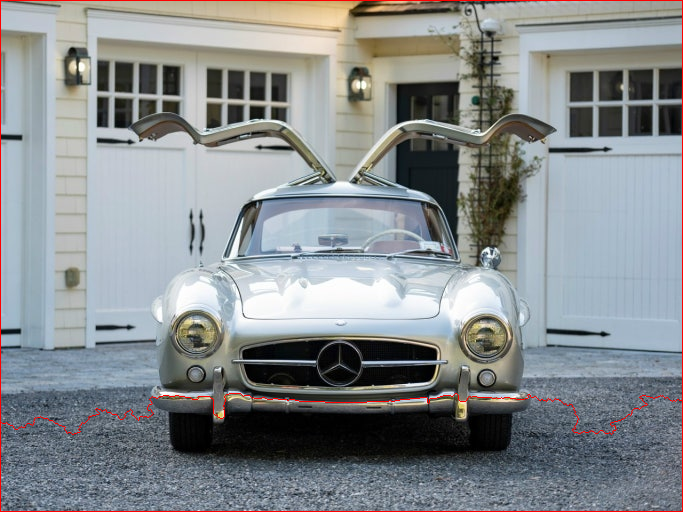

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

file_name = '300 SL.jpeg'
img = cv2.imread(file_name)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray, 160, 255, cv2.THRESH_BINARY_INV)

kernal = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
sure_bg = cv2.dilate(thresh, kernel)

dist_transform = cv2.distanceTransform(sure_bg, cv2.DIST_L2, 5)

_, sure_fg = cv2.threshold(dist_transform, 0.5 * dist_transform.max(), 255, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg)

unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(img, markers)

img[markers == -1] = [0, 0, 255]

cv2_imshow(img)
